In [5]:
%pip install tensorflow pandas scikit-learn matplotlib seaborn

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     -------------- ----------------------- 30.7/80.3 kB 435.7 kB/s eta 0:00:01
     --------------------------------- ---- 71.7/80.3 kB 787.7 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 744.9 kB/s eta 0:00:00
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached tensorflow-2.21.0-cp311-cp311-win_amd64.whl.metadata (4.5 kB)
  Using cached pandas-3.0.6-cp311-cp311-win_amd64.whl.metadata (19 kB)
  Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Us

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np, tensorflow as tf
from tensorflow.keras import layers

d = np.load("fashion_96x72.npz")
X_train, y_train = d["X_train"], d["y_train"]
X_val,   y_val   = d["X_val"],   d["y_val"]
X_test,  y_test  = d["X_test"],  d["y_test"]
class_names = list(d["class_names"])
NUM_CLASSES = len(class_names)
print(X_train.shape, X_train.dtype, X_val.shape, X_test.shape)
print(class_names)

(16364, 96, 72, 3) uint8 (3507, 96, 72, 3) (3507, 96, 72, 3)
[np.str_('Casual Shoes'), np.str_('Flip Flops'), np.str_('Handbags'), np.str_('Heels'), np.str_('Jeans'), np.str_('Kurtas'), np.str_('Shirts'), np.str_('Sports Shoes'), np.str_('Tops'), np.str_('Tshirts')]


In [3]:
from sklearn.utils.class_weight import compute_class_weight
w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = dict(enumerate(w))

In [4]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1, value_range=(0, 255)),
], name="data_augmentation")

In [5]:
base = tf.keras.applications.MobileNetV2(
    input_shape=(96, 72, 3), include_top=False, weights="imagenet")
base.trainable = False   # giai đoạn 1: đóng băng toàn bộ backbone

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_46120\2760008016.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 9s 1us/step


In [6]:
inputs = layers.Input(shape=(96, 72, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)          # giữ BatchNorm ở chế độ inference
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",   # nhãn là số nguyên 0..9
    metrics=["accuracy"])

In [11]:
cb = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("mnv2_stage1.keras", monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]
h1 = model.fit(X_train, y_train, validation_data=(X_val, y_val),
               epochs=15, batch_size=64, class_weight=class_weight, callbacks=cb)

Epoch 1/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 69s 243ms/step - accuracy: 0.6026 - loss: 1.2730 - val_accuracy: 0.7944 - val_loss: 0.5600 - learning_rate: 0.0010
Epoch 2/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 61s 237ms/step - accuracy: 0.7261 - loss: 0.7780 - val_accuracy: 0.7987 - val_loss: 0.5648 - learning_rate: 0.0010
Epoch 3/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 60s 235ms/step - accuracy: 0.7600 - loss: 0.6541 - val_accuracy: 0.7944 - val_loss: 0.5590 - learning_rate: 0.0010
Epoch 4/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 64s 248ms/step - accuracy: 0.7735 - loss: 0.5872 - val_accuracy: 0.8055 - val_loss: 0.5248 - learning_rate: 0.0010
Epoch 5/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 64s 249ms/step - accuracy: 0.7842 - loss: 0.5658 - val_accuracy: 0.8312 - val_loss: 0.4524 - learning_rate: 0.0010
Epoch 6/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 67s 261ms/step - accuracy: 0.7806 - loss: 0.5582 - val_accuracy: 0.8383 - val_loss: 0.4347 - learning_rate: 0.0010
Epoch 7/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 69s 209ms/step - accuracy: 0.7

In [12]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,296,416 (8.76 MB)

 Trainable params: 1,523,530 (5.81 MB)

 Non-trainable params: 747,264 (2.85 MB)

 Optimizer params: 25,622 (100.09 KB)

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

In [14]:
cb2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("mnv2_finetuned.keras", monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]
h2 = model.fit(X_train, y_train, validation_data=(X_val, y_val),
               epochs=20, batch_size=64, class_weight=class_weight,
               callbacks=cb2, verbose=2)

Epoch 1/20
256/256 - 94s - 368ms/step - accuracy: 0.8202 - loss: 0.4155 - val_accuracy: 0.8466 - val_loss: 0.3917 - learning_rate: 1.0000e-05
Epoch 2/20
256/256 - 145s - 566ms/step - accuracy: 0.8413 - loss: 0.3627 - val_accuracy: 0.8534 - val_loss: 0.3798 - learning_rate: 1.0000e-05
Epoch 3/20
256/256 - 82s - 319ms/step - accuracy: 0.8499 - loss: 0.3335 - val_accuracy: 0.8554 - val_loss: 0.3733 - learning_rate: 1.0000e-05
Epoch 4/20
256/256 - 78s - 305ms/step - accuracy: 0.8537 - loss: 0.3260 - val_accuracy: 0.8600 - val_loss: 0.3725 - learning_rate: 1.0000e-05
Epoch 5/20
256/256 - 77s - 300ms/step - accuracy: 0.8588 - loss: 0.3071 - val_accuracy: 0.8697 - val_loss: 0.3415 - learning_rate: 1.0000e-05
Epoch 6/20
256/256 - 76s - 297ms/step - accuracy: 0.8657 - loss: 0.2924 - val_accuracy: 0.8748 - val_loss: 0.3277 - learning_rate: 1.0000e-05
Epoch 7/20
256/256 - 75s - 292ms/step - accuracy: 0.8712 - loss: 0.2786 - val_accuracy: 0.8674 - val_loss: 0.3462 - learning_rate: 1.0000e-05
Epoch

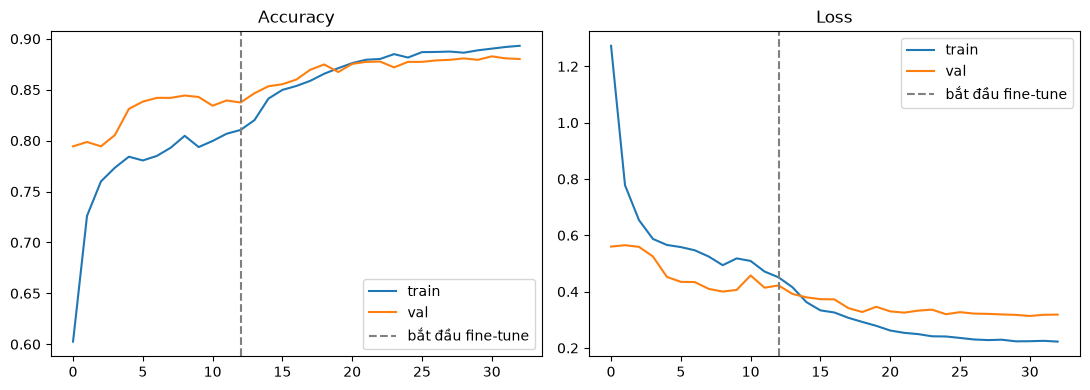

In [15]:
import matplotlib.pyplot as plt
acc  = h1.history["accuracy"] + h2.history["accuracy"]
vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
loss = h1.history["loss"] + h2.history["loss"]
vloss = h1.history["val_loss"] + h2.history["val_loss"]
n1 = len(h1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, tr, va, t in [(ax[0], acc, vacc, "Accuracy"), (ax[1], loss, vloss, "Loss")]:
    a.plot(tr, label="train"); a.plot(va, label="val")
    a.axvline(n1 - 1, ls="--", c="gray", label="bắt đầu fine-tune"); a.set_title(t); a.legend()
plt.tight_layout(); plt.savefig("mnv2_history.png", dpi=150); plt.show()

In [16]:
from sklearn.metrics import classification_report, confusion_matrix
class_names = [str(c) for c in class_names]
y_pred = model.predict(X_test, batch_size=64).argmax(axis=1)
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

55/55 ━━━━━━━━━━━━━━━━━━━━ 16s 251ms/step
              precision    recall  f1-score   support

Casual Shoes     0.8864    0.7494    0.8122       427
  Flip Flops     0.8874    0.9781    0.9306       137
    Handbags     0.9887    0.9962    0.9925       264
       Heels     0.9667    0.8788    0.9206       198
       Jeans     0.9891    1.0000    0.9945        91
      Kurtas     0.9688    0.8953    0.9306       277
      Shirts     0.9006    0.9398    0.9198       482
Sports Shoes     0.7292    0.8889    0.8012       306
        Tops     0.6277    0.8717    0.7299       265
     Tshirts     0.9707    0.8764    0.9212      1060

    accuracy                         0.8882      3507
   macro avg     0.8915    0.9075    0.8953      3507
weighted avg     0.9020    0.8882    0.8911      3507



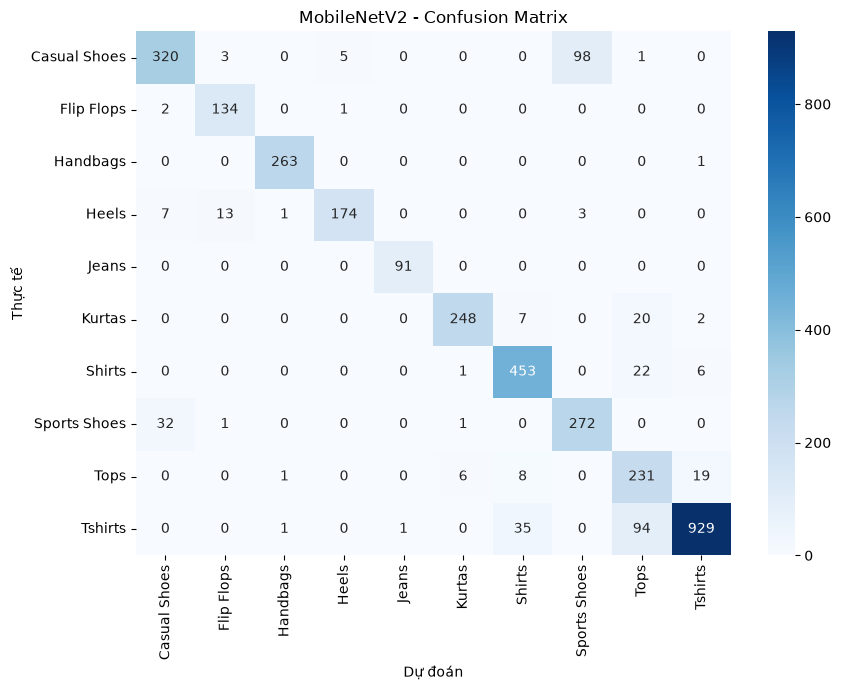

In [17]:
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title("MobileNetV2 - Confusion Matrix")
plt.tight_layout(); plt.savefig("mnv2_confusion_matrix.png", dpi=150); plt.show()

In [18]:
np.save("mnv2_y_pred.npy", y_pred)
np.save("mnv2_y_true.npy", y_test)
model.save("mnv2_final.keras")